# District clustering on LDA topic weights, one year at a time

Calls the functions in `source/analysis/lda_cleaned/lda_cluster.py` (same steps as `lda_clustering.ipynb`).
Set `YEAR` and `K` in the parameter cell, then **Restart & Run All**. Requires the `run_lda.py` outputs for that year
(`output/lda_cleaned/y<YEAR>/`); the cell below lists which runs exist.

Steps: standardize the district × topic matrix (lecture X\*), SVD, choose the number of clusters from the singular values
that beat a column-shuffled null, k-means on the top K−1 left singular vectors, then check partisanship and geography,
inspect the most culture-war-heavy cluster, and compare with IF-PCA on words. The last section summarizes every run.

Topic and cluster numbers are local to each fit, so compare years by topic **content** (the topic table), not by index.
**Clear outputs before committing** (section 5 prints meeting titles and transcript text).

In [14]:
from pathlib import Path
import os, sys, importlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "globals.json").exists())
os.chdir(REPO)
sys.path.insert(0, str(REPO / "source/analysis/lda_cleaned"))
import lda_cluster as lc
importlib.reload(lc)   # pick up edits to the .py without restarting

display(lc.AvailableRuns())

,year,k
0,2020,15
1,2022,15


In [28]:
YEAR, K = 2020, 15        # one of the runs listed above
NCLUST = None             # None: (# singular values above the shuffled null) + 1; or set an integer
STANDARDIZE = True        # True: standardized X* (lecture); False: raw weights + SCORE
MIN_TOPIC_MEAN = 0.02     # drop topics with mean weight below this before the SVD
MIN_MEETINGS = 1          # drop districts with fewer meetings
RUN_IFPCA = True          # section 6 builds the district x word matrix (about a minute)

## 1. Data and topics

In [29]:
meetings, district, T = lc.LoadDistricts(YEAR, K, MIN_MEETINGS)
topics = lc.LoadTopics(YEAR, K)
print(f"{YEAR}, K={K}: {len(meetings):,} meetings -> {len(district):,} districts; "
      f"median meetings per district {district['n_meetings'].median():.0f}")
with pd.option_context("display.max_colwidth", 120):
    display(topics.to_frame().assign(mean_weight=district[T].mean().round(3)))

2020, K=15: 10,337 meetings -> 1,087 districts; median meetings per district 8


,top_terms,mean_weight
t1,"th, week, day, year, days, meeting, calendar, did, report, january, work, monday, good, start, november",0.051
t2,"yes, mr, motion, second, board, item, miss, agenda, approve, vote, discussion, no, favor, aye, meeting",0.099
t3,"students, schools, district, board, community, high, years, education, county, student, year, evening, state, public...",0.060
t4,"students, year, really, work, student, data, learning, program, teachers, grade, level, look, curriculum, support, high",0.069
t5,"really, need, things, say, mean, make, people, kind, lot, question, look, way, did, said, maybe",0.114
t6,"health, students, staff, cases, county, positive, schools, mask, bus, people, masks, contact, department, day, risk",0.053
t7,"plan, students, learning, state, schools, survey, staff, option, information, make, health, plans, board, parents, c...",0.048
t8,"work, community, board, staff, really, dr, district, students, teachers, appreciate, children, support, miss, mr, me...",0.064
t9,"building, project, new, area, work, construction, projects, space, lot, site, high, street, facilities, use, city",0.045
t10,"students, services, families, able, technology, food, access, program, service, need, sure, working, staff, use, pro...",0.044


## 2. SVD and number of clusters

topics used: 15 of 15 (dropped: [])
observed : [50.8 50.2 44.  37.1 35.8 33.1 31.7 29.6 28.  26.6 25.  23.8 22.9 20.6
  0. ]
null 95% : [36.8 36.  35.4 34.9 34.4 34.  33.6 33.2 32.8 32.5 32.1 31.7 31.2 30.8
 30.2]
singular values above the shuffled null: 5


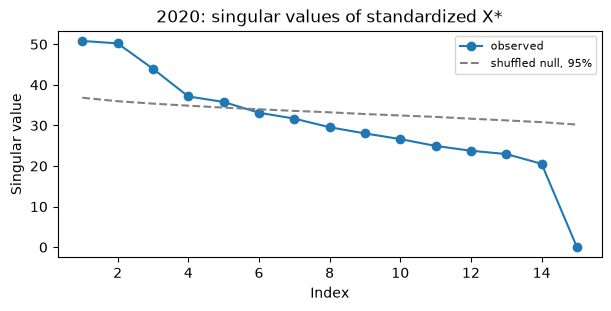

In [30]:
sp = lc.Decompose(district, T, STANDARDIZE, MIN_TOPIC_MEAN)
null_q, n_signal = lc.ParallelAnalysis(sp)
print(f"topics used: {len(sp['topics'])} of {K} (dropped: {sorted(set(T) - set(sp['topics']))})")
print("observed :", sp["s"].round(1))
print("null 95% :", null_q.round(1))
print(f"singular values above the shuffled null: {n_signal}")
lc.PlotScree(sp, null_q, title=f"{YEAR}: singular values of {'standardized X*' if STANDARDIZE else 'raw matrix'}")
plt.show()

In [31]:
# silhouette by embedding dimension r (rows) and number of clusters k (columns); the lecture rule is r = k - 1
display(lc.SilhouetteGrid(sp).round(2))

k,2,3,4,5,6,7,8
r,,,,,,,
1,0.54,0.53,0.54,0.53,0.53,0.53,0.53
2,0.32,0.34,0.33,0.32,0.32,0.32,0.33
3,0.22,0.23,0.25,0.24,0.23,0.23,0.23
4,0.17,0.18,0.19,0.20,0.19,0.19,0.19
5,0.14,0.14,0.15,0.16,0.17,0.17,0.15


## 3. Clusters

k = 3 clusters on r = 2 singular vectors
cluster
0    416
1    301
2    370


,low,high
vector,,
v1,"t2 (yes, mr, motion), t15 (year, budget, dollars), t11 (policy, board, district), t3 (students, schools, district)","t5 (really, need, things), t7 (plan, students, learning), t6 (health, students, staff), t14 (students, teachers, learning)"
v2,"t8 (work, community, board), t4 (students, year, really), t3 (students, schools, district), t13 (board, meeting, committee)","t5 (really, need, things), t9 (building, project, new), t1 (th, week, day), t12 (kids, did, really)"


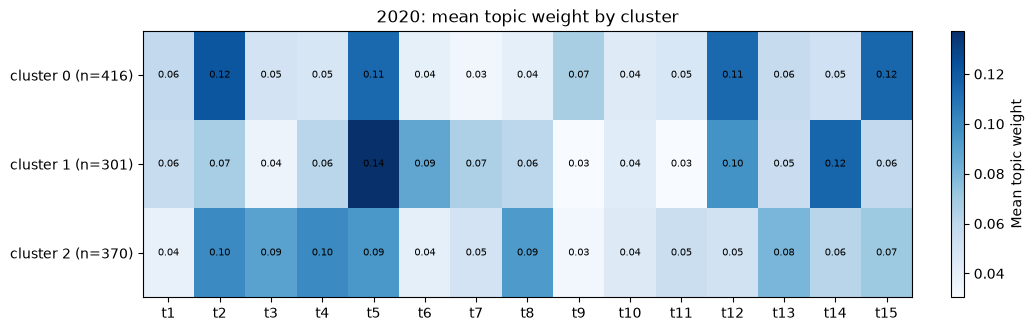

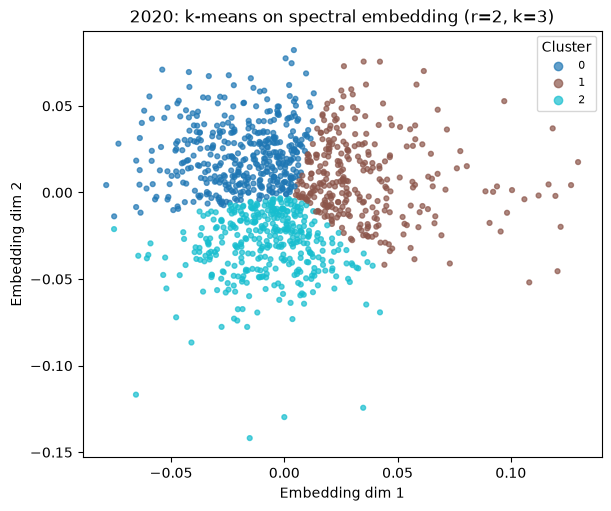

In [32]:
# nclust = NCLUST or max(n_signal + 1, 2)
nclust = 3
labels, Z = lc.Cluster(sp, nclust)
d = district.assign(cluster=labels)
print(f"k = {nclust} clusters on r = {nclust - 1} singular vectors")
print(d["cluster"].value_counts().sort_index().to_string())
with pd.option_context("display.max_colwidth", 200):
    display(lc.Loadings(sp, nclust - 1, topics))
lc.PlotProfile(d, T, title=f"{YEAR}: mean topic weight by cluster")
plt.show()
lc.PlotEmbedding(Z, labels, title=f"{YEAR}: k-means on spectral embedding (r={nclust - 1}, k={nclust})")
plt.show()

## 4. Partisanship and geography

merge: 100.0% matched; gop_2p_2020 99.8%, locale 100.0%


,count,mean,25%,50%,75%
cluster,,,,,
0,416.0,0.561,0.451,0.573,0.672
1,300.0,0.504,0.404,0.489,0.623
2,369.0,0.418,0.320,0.419,0.499


Kruskal-Wallis p = 9.99e-35; eta^2 (cluster -> GOP share) = 0.146; permutation p within locale = 0.0000


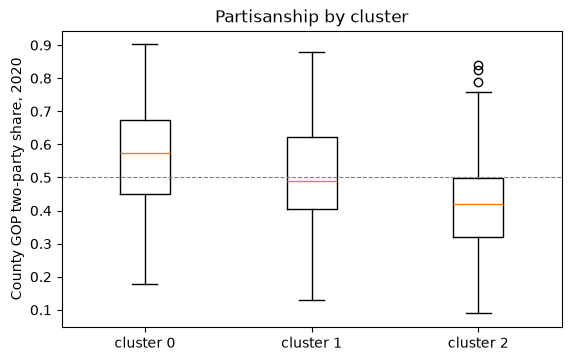

GOP share on embedding coordinates + locale dummies (OLS):


,spearman_rho,coef_per_sd,se,t
PC1,-0.0568,-0.0115,0.0039,-2.9765
PC2,0.5096,0.0550,0.0046,12.0442


In [33]:
d = lc.AddCovariates(d)
part = lc.Partisanship(d)
display(part["table"].round(3))
print(f"Kruskal-Wallis p = {part['kruskal_p']:.3g}; eta^2 (cluster -> GOP share) = {part['eta2']:.3f}; "
      f"permutation p within locale = {part['perm_p_within_locale']:.4f}")
lc.PlotPartisanship(d)
plt.show()

print("GOP share on embedding coordinates + locale dummies (OLS):")
display(lc.PCRegression(d, sp, nclust - 1).round(4))

locale: Cramer's V = 0.209, chi-square p = 8.991e-07  (row %)


locale,City,Rural,Suburb,Town
cluster,,,,
0,13.0,22.3,48.9,15.8
1,24.0,7.8,55.8,12.4
2,37.8,8.7,42.5,11.0


region: Cramer's V = 0.241, chi-square p = 3.003e-09  (row %)


region,Midwest,Northeast,South,West
cluster,,,,
0,33.7,32.6,22.8,10.9
1,20.2,26.4,48.1,5.4
2,35.4,19.7,20.5,24.4


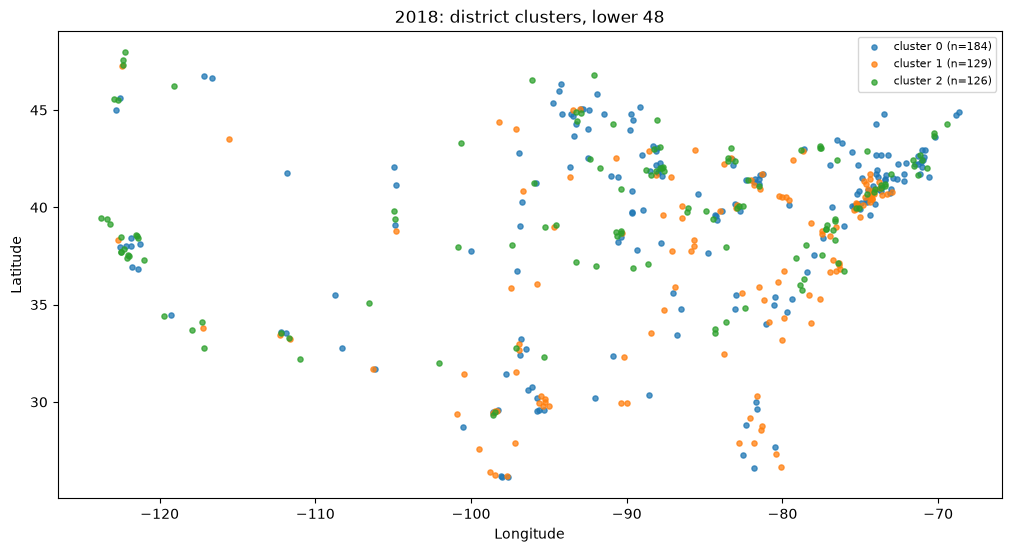

In [27]:
for var, g in lc.Geography(d).items():
    print(f"{var}: Cramer's V = {g['cramers_v']:.3f}, chi-square p = {g['p']:.4g}  (row %)")
    display(g["row_pct"].round(1))
lc.PlotMap(d, title=f"{YEAR}: district clusters, lower 48")
plt.show()

## 5. Inspect a cluster

Hot-button term rates by cluster; by default the cluster with the highest combined rate is inspected, using its two most
distinctive topics. Override `INSPECT_CLUSTER` / `INSPECT_TOPICS` to look at another one.

In [ ]:
rates = lc.TermRates(YEAR, meetings, d)
display(rates.round(2))

INSPECT_CLUSTER = None    # e.g. 2
INSPECT_TOPICS = None     # e.g. ["t7", "t14"]
cl = INSPECT_CLUSTER if INSPECT_CLUSTER is not None else int(rates.drop(index="curriculum").sum().idxmax())
tops = INSPECT_TOPICS or lc.DistinctiveTopics(d, T, cl)
print(f"cluster {cl}, topics {[lc.Short(topics, t) for t in tops]}")

top = lc.TopMeetings(meetings, d, cl, tops)
with pd.option_context("display.max_colwidth", 70):
    display(top.drop(columns="id").round({c: 2 for c in ["gop_2p_2020", *tops, "focus"]}))
for header, text in lc.Excerpts(YEAR, K, top, tops):
    print(f"\n### {header}\n{text}")

## 6. IF-PCA on words (dispersion screen + Higher Criticism)

In [ ]:
if RUN_IFPCA:
    ifp = lc.IFPCA(YEAR)
    print(f"HC keeps {ifp['khat']} of {ifp['n_words']} words; top 40:", ifp["top_words"])
    with pd.option_context("display.max_colwidth", 200):
        display(ifp["vectors"])
    cmp = lc.CompareIFPCA(d, ifp)
    print(f"ARI vs topic clusters: {cmp['ari']:.3f}")
    display(cmp["gop"].round(3))
    display(cmp["locale"].round(1))

## 7. All runs side by side

One row per available (year, K), each with its own number of clusters from the shuffled null. Uses the parameters above
except `YEAR` / `K`; no IF-PCA.

In [ ]:
summary = pd.DataFrame([lc.Summarize(r.year, r.k, NCLUST, STANDARDIZE, MIN_TOPIC_MEAN, MIN_MEETINGS)
                        for r in lc.AvailableRuns().itertuples()])
display(summary.round(3))